# Argentière YD — joint inversion of T(t) and five parameters

* Controls: **T(t)** (24 nodes, as anomaly to 2012–2021) + **P, T_s, DDF, A, τ_ref** (bold parameters, slide 4).
* Start: best T(t) of `results/argentiere_lg_100m_phys`, literature parameters.
* **Equal weight:** every control is a fraction z ∈ [0, 1] of its allowed range, one Adam learning rate, no prior on
  the parameters.
* T_present re-fitted to the geodetic balance at every iterate.
* Script `tools/run_argentiere_joint_inversion.py`; run `results/argentiere_lg_100m_joint`.

In [1]:
import json, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt, netCDF4, torch
os.chdir("..")
import tools.run_argentiere_inversion as R
import tools.run_argentiere_joint_inversion as J
%matplotlib inline
DX = 100
RUN = "results/argentiere_lg_100m_joint"
START = J.START
clim = R.CLIMATES["phys"]

/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


You are working on cpu device


## 1. Controls and their ranges

| control | start | range (z = 0 … 1) | gradient |
|---|---|---|---|
| T(t), 24 nodes | 100 m inversion | literature envelope | adjoint |
| P | 1.8 m/yr | 1.0 – 1.8 | adjoint |
| T_s | 9.4 °C | 7.9 – 10.9 | adjoint |
| DDF | 10 mm/K/d | 8 – 12 | adjoint |
| A | 78 MPa⁻³/yr | 52 – 117 | finite difference |
| τ_ref | 0.215 MPa | 0.10 – 0.25 | finite difference |

A and τ_ref act only through the emulator, whose gradient was unreliable (fixed-parameter notebook, §11):
one extra forward run each per iteration. ~50 min per iteration.

In [2]:
# Launch (hours): ./results/argentiere_lg_100m_joint/launch.sh
print(open(f"{RUN}/launch.sh").read())

#!/bin/bash
# Joint inversion: T(t) (as anomalies) + P, T_s, DDF, A, tau_ref, all as fractions of their ranges, one Adam lr.
# P allowed 1.0-1.8 m/yr. Starts from the best T(t) of results/argentiere_lg_100m_phys and the literature parameters.
cd /home/klleshi/Documents/InvertedGlacierEvolutionModel
source /home/klleshi/miniconda3/etc/profile.d/conda.sh
conda activate IGEM
export PYTHONPATH=.
IGEM_DEVICE=cuda:0 python -u tools/run_argentiere_joint_inversion.py --iters 30 --lr 0.03 --lr_min 0.005 \
  --out_dir results/argentiere_lg_100m_joint 2>&1 | tee results/argentiere_lg_100m_joint/inversion.log



## 2. Convergence: which controls move?

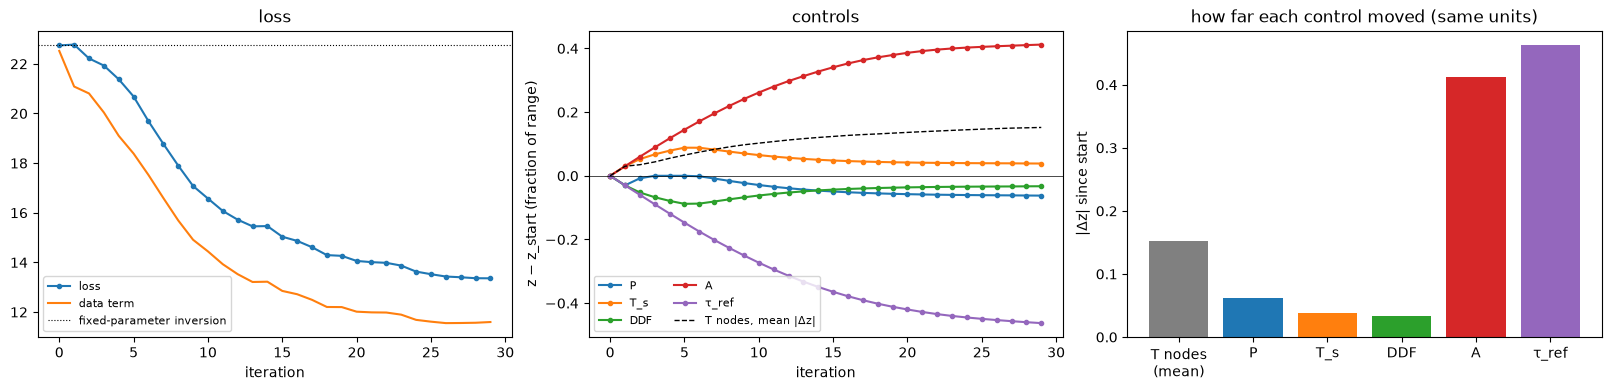

30 iterations, loss 22.74 -> 13.36 (best iter 29)


In [3]:
H = json.load(open(f"{RUN}/history.json")); h = H["history"]; n = H["n_nodes"]; keys = H["keys"]
z = np.array(h["z"]); gz = np.array(h["grad_z"])
names = {"precip": "P", "T_s": "T_s", "ddf": "DDF", "arrhenius": "A", "tau_ref": "τ_ref"}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), constrained_layout=True)
axes[0].plot(h["loss"], "o-", ms=3, label="loss"); axes[0].plot(h["data"], label="data term")
axes[0].axhline(22.74, c="k", ls=":", lw=.8, label="fixed-parameter inversion")
axes[0].set_xlabel("iteration"); axes[0].legend(fontsize=8); axes[0].set_title("loss")
for k, key in enumerate(keys):
    axes[1].plot(z[:, n + k] - z[0, n + k], "o-", ms=3, label=names[key])
axes[1].plot(np.abs(z[:, :n] - z[0, :n]).mean(1), "k--", lw=1, label="T nodes, mean |Δz|")
axes[1].axhline(0, c="k", lw=.5); axes[1].set_xlabel("iteration"); axes[1].set_ylabel("z − z_start (fraction of range)")
axes[1].legend(fontsize=8, ncol=2); axes[1].set_title("controls")
dz = np.abs(z[-1] - z[0])
axes[2].bar(["T nodes\n(mean)"] + [names[k] for k in keys], [dz[:n].mean()] + list(dz[n:]), color=["0.5"] + [f"C{k}" for k in range(len(keys))])
axes[2].set_ylabel("|Δz| since start"); axes[2].set_title("how far each control moved (same units)")
plt.show()
print(f"{len(h['loss'])} iterations, loss {h['loss'][0]:.2f} -> {min(h['loss']):.2f} (best iter {H['best']['iter']})")

## 3. Temperature and parameters at the best iterate

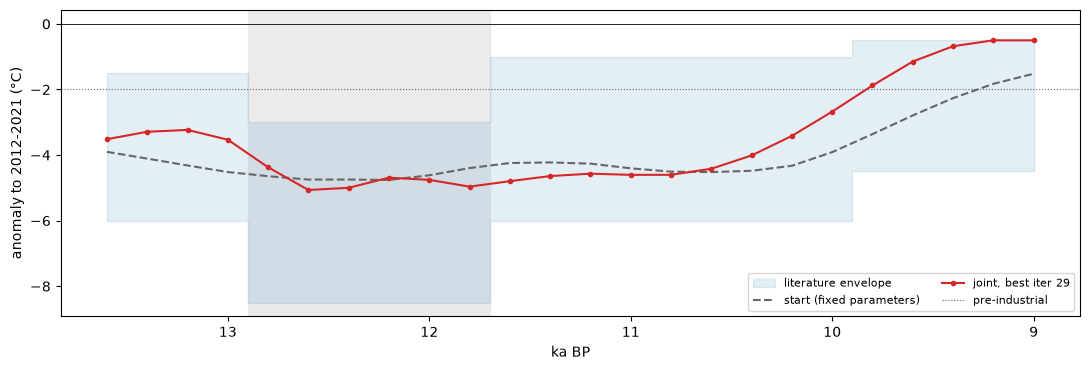

Younger Dryas anomaly: start -4.65 °C, joint -4.81 °C


,start,best,range
precip,1.800,1.750,1.0 – 1.8
T_s,9.400,9.516,7.9 – 10.9
ddf,10.000,9.869,8.0 – 12.0
arrhenius,78.000,104.783,52.0 – 117.0
tau_ref,0.215,0.146,0.1 – 0.25
T_present,-0.890,-1.001,NaN


In [4]:
b = H["best"]; s0 = h["state"][0]
nt = np.array(H["node_times"]); ka = (1950 - nt) / 1000
lo_a, hi_a = J.anomaly_bounds(nt)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(ka, lo_a, hi_a, step="mid", color="C0", alpha=.12, label="literature envelope")
ax.axvspan(12.9, 11.7, color="0.92", zorder=0)
ax.plot(ka, np.array(s0["T"]) - s0["T_present"], "--", c="0.4", label="start (fixed parameters)")
ax.plot(ka, np.array(b["T"]) - b["T_present"], "o-", c="C3", ms=3, label=f"joint, best iter {b['iter']}")
ax.axhline(0, c="k", lw=.6); ax.axhline(-R.PRESENT_MINUS_PREINDUSTRIAL, c="0.4", ls=":", lw=.8, label="pre-industrial")
ax.invert_xaxis(); ax.set_xlabel("ka BP"); ax.set_ylabel("anomaly to 2012-2021 (°C)"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
yd = (ka <= 12.9) & (ka >= 11.7)
print(f"Younger Dryas anomaly: start {np.mean(np.array(s0['T'])[yd]) - s0['T_present']:+.2f} °C, joint {np.mean(np.array(b['T'])[yd]) - b['T_present']:+.2f} °C")
pd.DataFrame({"start": {**s0["params"], "T_present": s0["T_present"]}, "best": {**b["params"], "T_present": b["T_present"]},
              "range": {k: f"{J.RANGES[k][0]} – {J.RANGES[k][1]}" for k in J.RANGES}}).round(3)

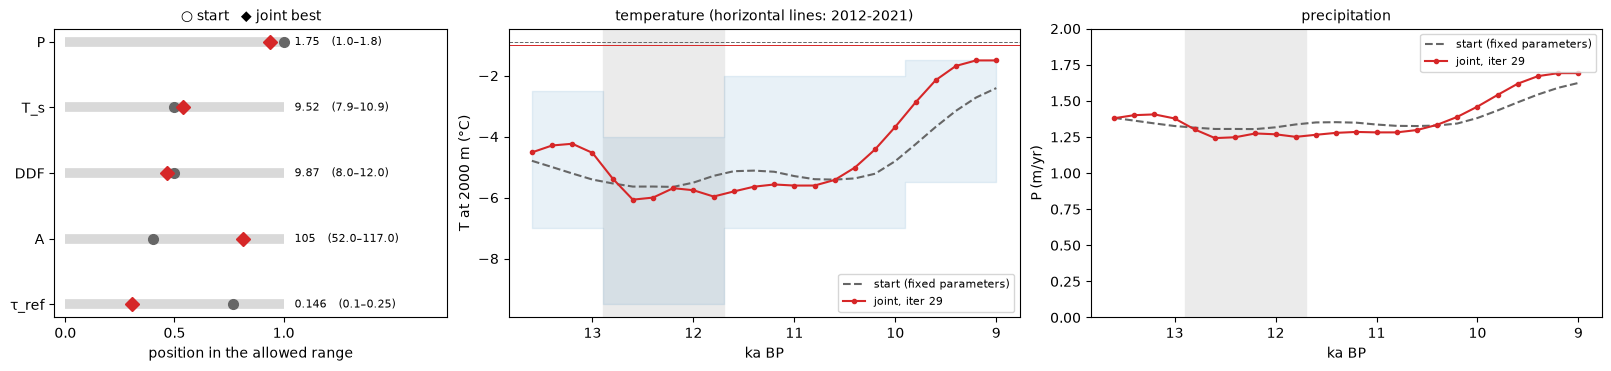

In [5]:
# Parameters on their allowed ranges; absolute temperature and precipitation (+7 %/°C) of start and best
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), constrained_layout=True, gridspec_kw=dict(width_ratios=[1, 1.3, 1.3]))
ax = axes[0]
for i, k in enumerate(keys):
    lo, hi = J.RANGES[k]; frac = lambda v: (v - lo) / (hi - lo)
    ax.plot([0, 1], [i, i], c="0.85", lw=7, solid_capstyle="butt")
    ax.plot(frac(s0["params"][k]), i, "o", c="0.4", ms=7)
    ax.plot(frac(b["params"][k]), i, "D", c="C3", ms=7)
    ax.text(1.05, i, f"{b['params'][k]:.3g}   ({lo}–{hi})", va="center", fontsize=8)
ax.set_yticks(range(len(keys))); ax.set_yticklabels([names[k] for k in keys]); ax.invert_yaxis()
ax.set_xlim(-.05, 1.75); ax.set_xticks([0, .5, 1]); ax.set_xlabel("position in the allowed range")
ax.set_title("○ start   ◆ joint best", fontsize=10)
for st, lab, sty in ((s0, "start (fixed parameters)", dict(c="0.4", ls="--")), (b, f"joint, iter {b['iter']}", dict(c="C3", marker="o", ms=3))):
    T = np.array(st["T"])
    axes[1].plot(ka, T, label=lab, **sty)
    axes[1].axhline(st["T_present"], lw=.7, **{k: v for k, v in sty.items() if k in ("c", "ls")})
    axes[2].plot(ka, st["params"]["precip"] * (1 + clim["precip_cc"]) ** (T - st["T_present"]), label=lab, **sty)
axes[1].fill_between(ka, lo_a + b["T_present"], hi_a + b["T_present"], step="mid", color="C0", alpha=.1)
axes[1].set_ylabel("T at 2000 m (°C)"); axes[1].set_title("temperature (horizontal lines: 2012-2021)", fontsize=10)
axes[2].set_ylabel("P (m/yr)"); axes[2].set_ylim(0, 2); axes[2].set_title("precipitation", fontsize=10)
for a in axes[1:]:
    a.axvspan(12.9, 11.7, color="0.92", zorder=0); a.invert_xaxis(); a.set_xlabel("ka BP"); a.legend(fontsize=8)
plt.show()

* Flow parameters moved most: τ_ref 0.215 → 0.146 MPa, A 78 → 105. P, T_s, DDF barely moved.
* YD −4.81 °C vs 2012–2021 (start −4.65); the post-10 ka warming is steeper; 9.2–9.0 ka on the warm bound.
* P(t) stays 1.25–1.7 m/yr.

## 4. Fit per landform: start vs best

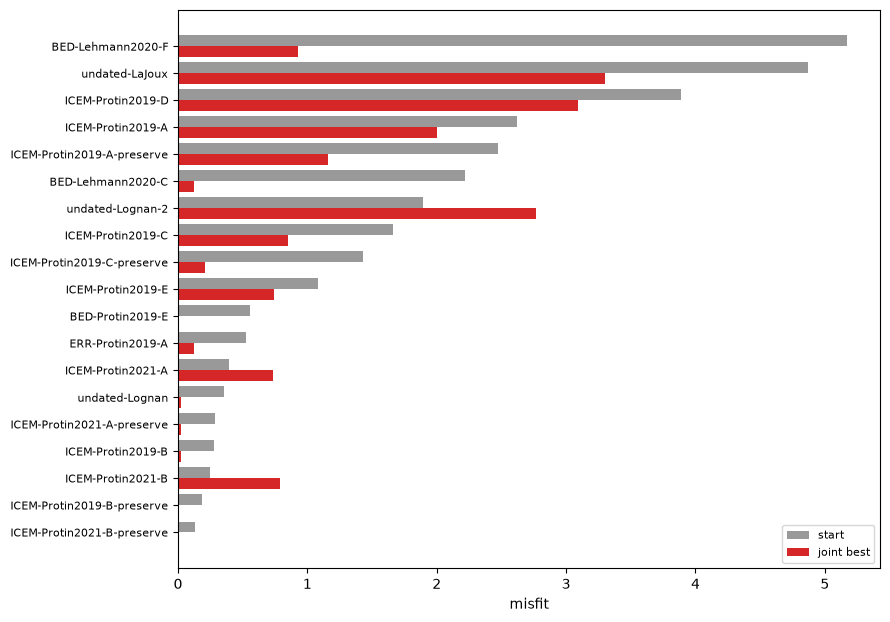

In [6]:
t0, tb = h["terms"][0], h["terms"][H["best"]["iter"]]
fit = pd.DataFrame({"start": t0, "best": tb}).sort_values("start", ascending=False)
fit = fit[(fit.start > 0.01) | (fit.best > 0.01)]
fig, ax = plt.subplots(figsize=(9, 0.28 * len(fit) + 1))
y = np.arange(len(fit))
ax.barh(y - .2, fit.start, .4, color="0.6", label="start"); ax.barh(y + .2, fit.best, .4, color="C3", label="joint best")
ax.set_yticks(y); ax.set_yticklabels(fit.index, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("misfit"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.1 Distance to each constraint

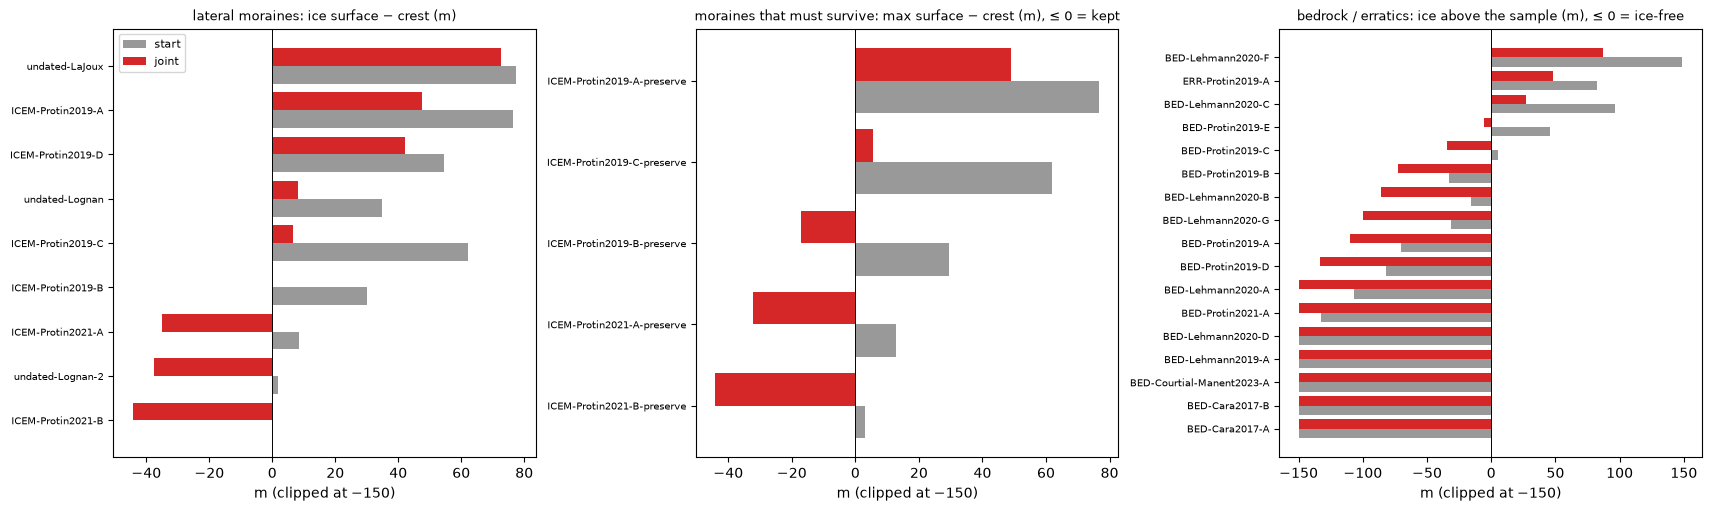

La Joux J2 frontal moraine, terminus − moraine: {'start': '-129 m', 'joint': '-0 m'}


In [7]:
# Distance to each constraint in metres: start (fixed parameters) vs joint best
from data.loader import load_argentiere
from core.moraine_obs import select
geo, obs = load_argentiere(DX, mask=R.WINDOWS["lg"]["mask"], valley=True)
obs = select(obs, R.WINDOWS["lg"]["t_start"], R.WINDOWS["lg"]["t_end"], R.WINDOWS["lg"]["dt_snap"])
kind = {o["id"]: o["kind"] for o in obs}
desc = {"start": json.load(open(f"{START}/final_terms.json"))["describe"], "joint": json.load(open(f"{RUN}/final_terms.json"))["describe"]}
groups = [("lateral_v", "dz_m", "lateral moraines: ice surface − crest (m)"),
          ("preserve", "dz_m", "moraines that must survive: max surface − crest (m), ≤ 0 = kept"),
          ("icefree_v", "dz_m", "bedrock / erratics: ice above the sample (m), ≤ 0 = ice-free")]
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, (kd, key, ttl) in zip(axes, groups):
    ids = [i for i in kind if kind[i] == kd]
    v = pd.DataFrame({r: [desc[r].get(i, {}).get(key, np.nan) for i in ids] for r in desc}, index=ids).dropna().sort_values("joint")
    y = np.arange(len(v))
    ax.barh(y - .2, v.start.clip(-150), .4, color="0.6", label="start"); ax.barh(y + .2, v.joint.clip(-150), .4, color="C3", label="joint")
    ax.axvline(0, c="k", lw=.7); ax.set_yticks(y); ax.set_yticklabels(v.index, fontsize=7); ax.set_title(ttl, fontsize=9)
    ax.set_xlabel("m (clipped at −150)")
axes[0].legend(fontsize=8)
plt.show()
j2d = {r: desc[r]["ICEM-Protin2019-E"]["dL_m"] for r in desc}
print("La Joux J2 frontal moraine, terminus − moraine:", {r: f"{v:+.0f} m" for r, v in j2d.items()})

* La Joux J2 frontal moraine: reached exactly (−129 m → 0 m).
* Lognan laterals: L3 62 → 7 m, L2 30 → 0 m, L1 76 → 48 m too high; La Joux lines (J1, undated) still 42–73 m too high.
* Bedrock under ice: 5 → 3 samples (Lehmann2020-F 87 m, La Joux erratic 48 m, Lehmann2020-C 26 m).
* L1 still overridden by 49 m after it formed.

## 5. The glacier at the dated stands (after the run)

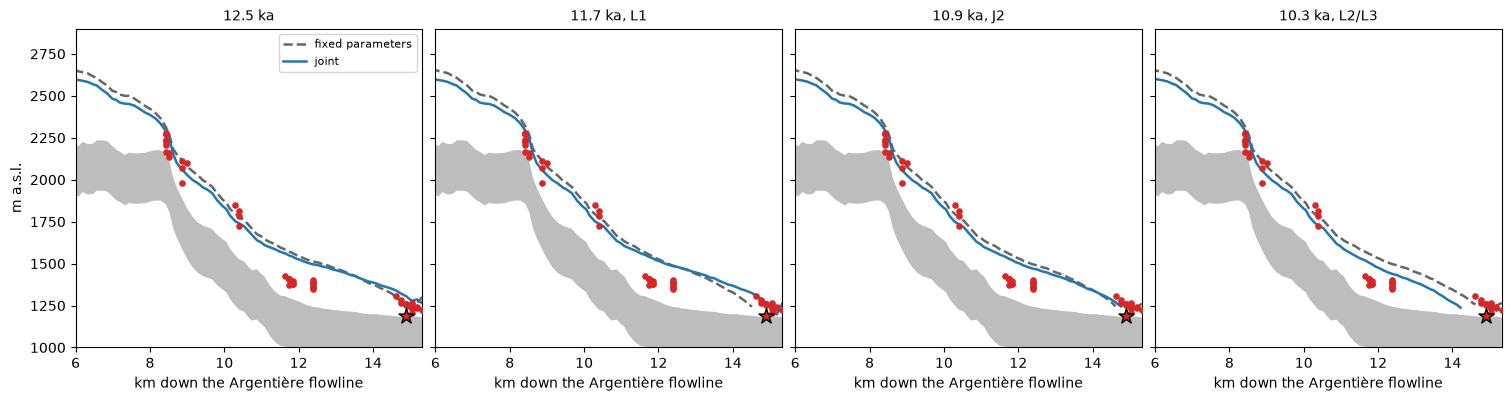

In [8]:
from matplotlib.colors import LightSource
from data.loader import load_argentiere
from core.moraine_obs import select, terminus_position
if not os.path.exists(f"{RUN}/final_fields.npz"):
    print("run not finished yet")
else:
    geo, obs = load_argentiere(DX, mask=R.WINDOWS["lg"]["mask"], valley=True)
    obs = select(obs, R.WINDOWS["lg"]["t_start"], R.WINDOWS["lg"]["t_end"], R.WINDOWS["lg"]["dt_snap"])
    by = {o["id"]: o for o in obs}; FL = geo["flowlines"]["Argentiere"]; j2 = by["ICEM-Protin2019-E"]
    nc = netCDF4.Dataset(f"data/Argentiere/argentiere_{DX}m.nc"); bed = np.asarray(nc["topg"][:]); nc.close()
    runs = {"fixed parameters": np.load(f"{START}/video_fields.npz"), "joint": np.load(f"{RUN}/final_fields.npz")}
    cells = FL.cells[:FL.stop]; s_km = FL.s[:FL.stop] / 1000; bedf = bed.ravel()
    pos = {int(c): float(si) for c, si in zip(FL.cells[:FL.stop], FL.s[:FL.stop])}
    stands = [(12.5, "12.5 ka"), (11.66, "11.7 ka, L1"), (10.9, "10.9 ka, J2"), (10.35, "10.3 ka, L2/L3")]
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True, constrained_layout=True)
    for ax, (k, ttl) in zip(axes, stands):
        ax.fill_between(s_km, bedf[cells] - 300, bedf[cells], color="#bdbdbd", lw=0)
        for (name, f), col, ls in zip(runs.items(), ("0.4", "C0"), ("--", "-")):
            Hk = f["H"][int(np.argmin(abs(f["times"] - (1950 - k * 1000))))].ravel()[cells]
            ax.plot(s_km, np.where(Hk > 1, bedf[cells] + Hk, np.nan), c=col, ls=ls, lw=1.8, label=name)
        for oid in ("ICEM-Protin2019-A", "ICEM-Protin2019-B", "ICEM-Protin2019-C", "ICEM-Protin2019-D", "undated-LaJoux"):
            o = by[oid]; ax.scatter([pos[int(c)] / 1000 for c in o["axis"].cpu().numpy()], o["z"].cpu().numpy(), s=14, c="#d62728", zorder=5)
        ax.scatter([j2["s_obs"] / 1000], [bedf[cells][int(np.argmin(abs(FL.s[:FL.stop] - j2["s_obs"])))]], marker="*", s=130, c="#d62728", ec="k", zorder=6)
        ax.set_title(ttl, fontsize=10); ax.set_xlabel("km down the Argentière flowline"); ax.set_xlim(6, s_km[-1])
    axes[0].set_ylabel("m a.s.l."); axes[0].set_ylim(1000, 2900); axes[0].legend(fontsize=8)
    plt.show()

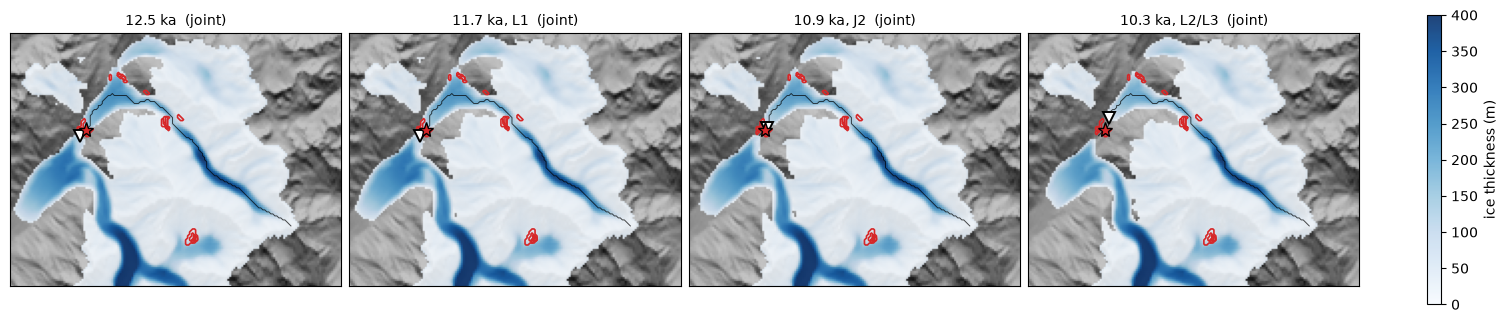

In [9]:
# Maps of the joint best run at the dated stands: ▽ modelled terminus, ★ J2, red: moraine crests
nc = netCDF4.Dataset(f"data/Argentiere/argentiere_{DX}m.nc"); g = lambda k: np.asarray(nc[k][:])
xk, yk = g("x") / 1000, g("y") / 1000; flip = yk[0] > yk[-1]
lines = {v[5:]: g(v) for v in nc.variables if v.startswith("line_")}; nc.close()
hs = LightSource(azdeg=180, altdeg=40).hillshade(bed, vert_exag=1, dx=DX, dy=DX); ext = [xk[0], xk[-1], min(yk), max(yk)]
fj = runs["joint"]; snap = lambda kk: fj["H"][int(np.argmin(abs(fj["times"] - (1950 - kk * 1000))))]
def term(Hm):
    path = torch.tensor(FL.active[FL.start:]); s = torch.tensor(FL.s[FL.start: FL.stop], dtype=torch.float32)
    return float(terminus_position(torch.tensor(Hm, dtype=torch.float32), path, s))
iy, ix = np.unravel_index(FL.cells[:FL.stop], bed.shape)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), constrained_layout=True)
for ax, (kk, ttl) in zip(axes, stands):
    Hm = snap(kk); Hn = np.where(Hm > 1, Hm, np.nan)
    ax.imshow(hs if flip else hs[::-1], extent=ext, cmap="gray", vmin=0, vmax=1.3)
    im = ax.imshow(Hn if flip else Hn[::-1], extent=ext, cmap="Blues", vmin=0, vmax=400, alpha=.9)
    for L in lines.values():
        ax.contour(xk, yk, L, levels=[.5], colors="#d62728", linewidths=1.2)
    ax.plot(xk[ix], yk[iy], c="k", lw=.7, alpha=.7)
    kt = int(np.argmin(abs(FL.s[:FL.stop] - term(Hm))))
    ax.plot(xk[ix[kt]], yk[iy[kt]], marker="v", c="k", mfc="white", ms=8, mew=1.4, ls="none")
    kj = int(np.argmin(abs(FL.s[:FL.stop] - j2["s_obs"])))
    ax.plot(xk[ix[kj]], yk[iy[kj]], marker="*", c="#d62728", mec="k", ms=11, ls="none")
    ax.set_xlim(xk[ix.min()] - 3.5, xk[ix.max()] + 2.5); ax.set_ylim(yk[iy].min() - 3, yk[iy].max() + 3)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{ttl}  (joint)", fontsize=10)
fig.colorbar(im, ax=axes, shrink=.8, label="ice thickness (m)")
plt.show()

### 5.1 Terminus through time

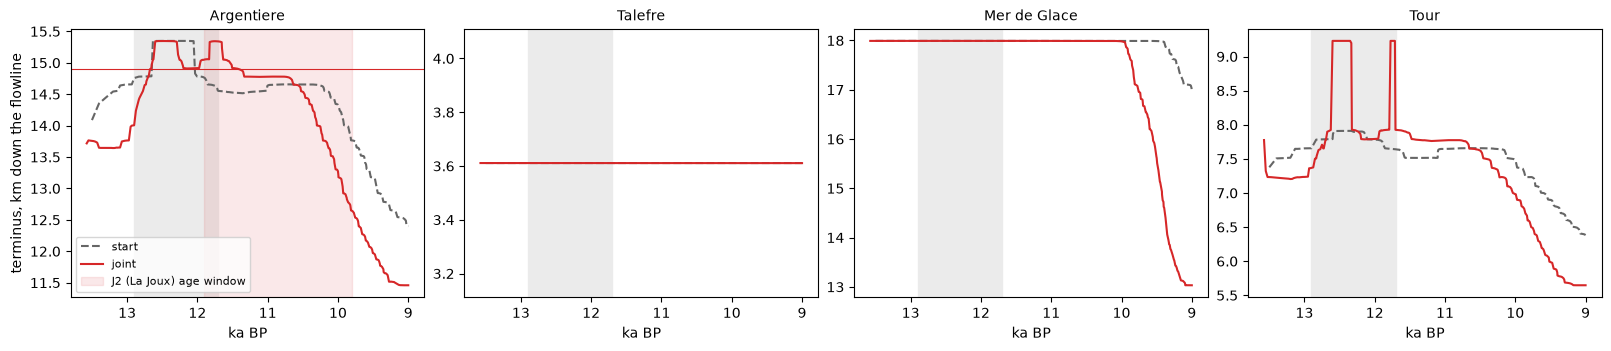

In [10]:
# Terminus position along each valley's flowline through time: start vs joint; J2 age window and position
term_runs = {"start": json.load(open(f"{START}/final_terms.json"))["termini"], "joint": json.load(open(f"{RUN}/final_terms.json"))["termini"]}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), constrained_layout=True)
for ax, valley in zip(axes, term_runs["joint"]):
    for (r, tr), sty in zip(term_runs.items(), (dict(c="0.4", ls="--"), dict(c="C3"))):
        t = np.array(sorted(tr[valley], key=float), dtype=float)
        L = np.array([tr[valley][k] for k in sorted(tr[valley], key=float)], dtype=float)
        ax.plot((1950 - t) / 1000, L / 1000, label=r, **sty)
    if valley == "Argentiere":
        ax.axhline(j2["s_obs"] / 1000, c="#d62728", lw=.8)
        ax.axvspan((1950 - j2["t1"]) / 1000, (1950 - j2["t0"]) / 1000, color="#d62728", alpha=.1, label="J2 (La Joux) age window")
    lo_, hi_ = ax.get_ylim()
    if hi_ - lo_ < 1:                               # a terminus that never moves: show it on a 1 km scale
        mid = .5 * (lo_ + hi_); ax.set_ylim(mid - .5, mid + .5)
    ax.axvspan(12.9, 11.7, color="0.92", zorder=0)
    ax.invert_xaxis(); ax.set_xlabel("ka BP"); ax.set_title(valley, fontsize=10)
axes[0].set_ylabel("terminus, km down the flowline"); axes[0].legend(fontsize=8)
plt.show()

* Argentière sits at J2 from ~11.9 to 10.8 ka, then retreats earlier and faster than in the start run.
* Mer de Glace and Tour also retreat ~0.5 kyr earlier: the warmer early Holocene.

## 6. Present-day mass balance with the joint parameters

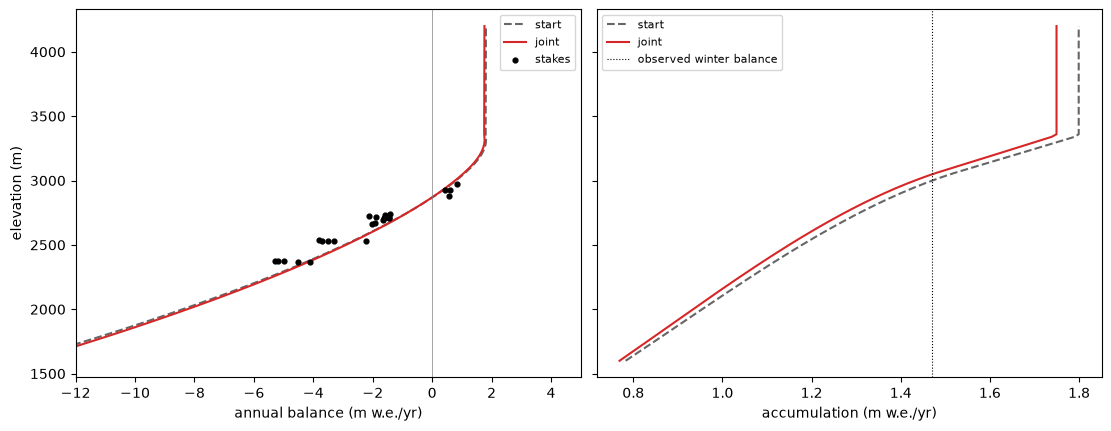

,stake rmse (m w.e.),glacier-wide balance,glacier-wide accumulation
run,,,
start,0.66,-0.68,1.40
joint,0.69,-0.68,1.36
observed,,-0.66,1.47


In [11]:
# Present-day (2012-2021) mass balance with the start and the joint parameters, against stakes and the geodetic balance
from core.climate import apply_lapse_rate, compute_negative_temperature_ratio, compute_integral_positive_temperature
st = pd.read_csv("data/Argentiere/sources/present/SMB_argentiere_2012-2021_utm32N.csv")
nc = netCDF4.Dataset(f"data/Argentiere/argentiere_{DX}m.nc")
zs = (np.asarray(nc["topg"][:]) + 0.5 * (np.asarray(nc["thk_2012"][:]) + np.asarray(nc["thk_2021"][:])))[np.asarray(nc["argentiere_2012"][:]) > .5]
nc.close()
MF_PER_DDF = clim["melt_factor"] / 10.0          # melt factor (m w.e./K/month) per mm/K/d
def smb(z, st_):
    p = st_["params"]
    Tm = apply_lapse_rate(torch.tensor(np.asarray(z, float)), torch.tensor(st_["T_present"], dtype=torch.float64), z_ref=clim["z_ref"])
    Ts = torch.tensor(p["T_s"], dtype=torch.float64)
    acc = (p["precip"] * compute_negative_temperature_ratio(Tm, Ts)).numpy()
    return acc, acc - (p["ddf"] * MF_PER_DDF * compute_integral_positive_temperature(Tm, Ts)).numpy()
zz = np.linspace(1600, 4200, 131); rows = []
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, constrained_layout=True)
for (lab, st_), sty in zip((("start", s0), ("joint", b)), (dict(c="0.4", ls="--"), dict(c="C3"))):
    a, m = smb(zz, st_); ax[0].plot(m, zz, label=lab, **sty); ax[1].plot(a, zz, label=lab, **sty)
    a_s, m_s = smb(st.Alt.values, st_); a_g, m_g = smb(zs, st_)
    rows.append({"run": lab, "stake rmse (m w.e.)": np.sqrt(np.mean((m_s - st.iloc[:, 3].values) ** 2)),
                 "glacier-wide balance": m_g.mean(), "glacier-wide accumulation": a_g.mean()})
rows.append({"run": "observed", "glacier-wide balance": -0.66, "glacier-wide accumulation": 1.47})
ax[0].scatter(st.iloc[:, 3], st.Alt, c="k", s=12, zorder=5, label="stakes"); ax[0].axvline(0, c="grey", lw=.5)
ax[0].set_xlim(-12, 5); ax[0].set_xlabel("annual balance (m w.e./yr)"); ax[0].set_ylabel("elevation (m)"); ax[0].legend(fontsize=8)
ax[1].axvline(1.47, c="k", ls=":", lw=.8, label="observed winter balance"); ax[1].set_xlabel("accumulation (m w.e./yr)"); ax[1].legend(fontsize=8)
plt.show()
pd.DataFrame(rows).set_index("run").round(2).fillna("")

* Present-day balance unchanged: glacier-wide −0.68 (obs −0.66), stake rmse 0.66 → 0.69, accumulation 1.40 → 1.36 (obs 1.47).

## 7. Video

`results/argentiere_lg_100m_joint/video/argentiere_lateglacial_100m_joint.mp4` (13.6 → 9.0 ka, every 25 yr).